In [374]:
# pip install kagglehub
# pip install glob

In [375]:
# downloading dataser from kaggle
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("ashwingupta3012/male-and-female-faces-dataset")

# print("Path to dataset files:", path)

In [376]:
# importing libraries
from glob import glob
import cv2
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [377]:
male_path = glob("Male and Female face dataset\Male Faces\*")
female_path = glob("Male and Female face dataset\Female Faces\*")

Text(0.5, 1.0, 'Female Image Sample')

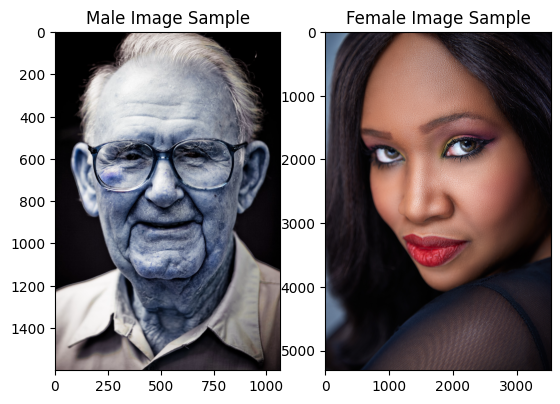

In [378]:
# male_image
male_image = cv2.imread(male_path[0])
female_image = plt.imread(female_path[0])

plt.subplot(1,2,1)
plt.imshow(male_image)
plt.title("Male Image Sample")
plt.subplot(1,2,2)
plt.imshow(female_image)
plt.title("Female Image Sample")

In [379]:
# defining and loading the model
my_model = cv2.CascadeClassifier("haarcascade_frontalface_default.xml")

In [382]:
# defining a function to crop faces
def crop_face(images,model,gender):
    """
    The function takes three arguments, image path list, model and gender.
    We iterate on image path list and read images one by one, convert image in to grayscale.
    Then detect face on grayscale image using the model, then crop the real image using coordinates given by model.
    Then I am saving the cropped faces as png.
    """

    # iterating on images one by one
    for i,data in enumerate(images):

        # reading the images using cv2
        img = cv2.imread(data)

        # converting the image into grayscale image
        img_gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)

        # detecting the face on gray scale image and saving corrdinates of face
        cordinates = model.detectMultiScale(img_gray,scaleFactor=1.1,minNeighbors=5)

        # now using the coordinates to crop the face in real image
        for x,y,w,h in cordinates:
            cropped_face = img[y:y+h,x:x+w]
        
        #cropped_face = cropped_face / 255
        # saving the cropped face image
        cv2.imwrite(f"./cropped/{gender}/{i}.png",cropped_face)



In [383]:
crop_face(female_path,my_model,"female")

KeyboardInterrupt: 

### Image resizing
- we have successfully cropped faces from images and saved in a directory, now we will resize each image to one size so that every image have a uniform size.

In [4]:
# making a data frame of male and female cropped faces
male_cropped = glob("cropped\male\*")

# female cropped images
female_cropped = glob("cropped\\female\\*")

In [5]:
len(female_cropped)

100

In [6]:
import pandas as pd

In [7]:
# now creating male dataframe
male_cropped_df = pd.DataFrame({"path":male_cropped})

female_cropped_df = pd.DataFrame({"path":female_cropped})

In [8]:
# creating a gender column in male df
male_cropped_df["gender"] = "male"

# creating a gender column in female df
female_cropped_df["gender"] = "female"


In [9]:
len(male_cropped)

100

In [10]:
female_cropped_df.shape

(100, 2)

In [11]:
# combining male and femal df into one
combined_df = pd.concat([male_cropped_df,female_cropped_df],axis=0)

In [12]:
combined_df.head()

,path,gender
0,cropped\male\0.png,male
1,cropped\male\1.png,male
2,cropped\male\10.png,male
3,cropped\male\11.png,male
4,cropped\male\12.png,male


In [15]:
# making sure that images from both classes exist
combined_df["gender"].value_counts()

male      100
female    100
Name: gender, dtype: int64

In [31]:
# now defining a function to get the size of each image
def image_size(img):
    img_array = cv2.imread(img)
    return img_array.shape[0]

In [32]:
# creating a column that contains the pixel size of each image
combined_df["size"] =  combined_df["path"].apply(image_size)

In [33]:
combined_df.head()

,path,gender,size
0,cropped\male\0.png,male,129
1,cropped\male\1.png,male,402
2,cropped\male\10.png,male,2716
3,cropped\male\11.png,male,477
4,cropped\male\12.png,male,1795


In [34]:
# checking for null values
combined_df.isna().sum()

path      0
gender    0
size      0
dtype: int64

In [35]:
# getting basic statistics about image sizes
combined_df.describe()

,size
count,200.000000
mean,738.030000
std,759.791706
min,42.000000
25%,301.750000
50%,478.000000
75%,713.250000
max,3374.000000


In [91]:
# defining a function to resize each image
def resize_image(img_path):
    
    # reading the image from its path
    img = cv2.imread(img_path)

    # converting the image into grayscale image
    img_gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)

    # getting size of grayscale image
    img_gray_size = img_gray.shape[0]

    # applying a confition if image pixel size is greater than or equal to 100 shrink it to 100 by 100
    if img_gray_size >= 100:
        resized_img = cv2.resize(img_gray,(100,100),cv2.INTER_AREA) # Inter Area is used for shrinking the image
    else:

        # if the image size is less than 100 pixels, expand the image size to 100 by 100
        resized_img = cv2.resize(img_gray,(100,100),cv2.INTER_CUBIC) # Inter CUBIC is used for expanding the image

    # flattening the 2d array of image into 1d array
    return resized_img.flatten()

In [92]:
# creating a column data where resize image data is stored
combined_df["data"] = combined_df["path"].apply(resize_image)

In [93]:
df = combined_df["data"].apply(pd.Series)

In [94]:
df.iloc[0,:].values.reshape((100,100))

array([[137, 137, 138, ..., 139, 137, 135],
       [134, 136, 138, ..., 138, 137, 135],
       [135, 136, 136, ..., 138, 136, 134],
       ...,
       [148, 149, 151, ..., 104, 104, 104],
       [148, 149, 150, ..., 104, 104, 104],
       [147, 148, 149, ..., 102, 103, 103]], dtype=uint8)

In [ ]:
image = df.iloc[5,:].values.reshape(100,100)

In [ ]:
df["gender"] = combined_df["gender"].copy()

In [102]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,9991,9992,9993,9994,9995,9996,9997,9998,9999,gender
0,137,137,138,140,140,141,142,143,142,141,...,103,103,103,103,102,102,102,103,103,male
1,188,149,71,63,49,44,59,58,43,55,...,220,222,222,222,222,222,222,222,222,male
2,12,15,13,14,13,14,25,38,37,36,...,49,50,40,37,45,68,76,64,44,male
3,42,40,39,38,37,39,46,55,63,59,...,33,32,32,31,33,33,32,31,33,male
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,7,23,0,0,0,male


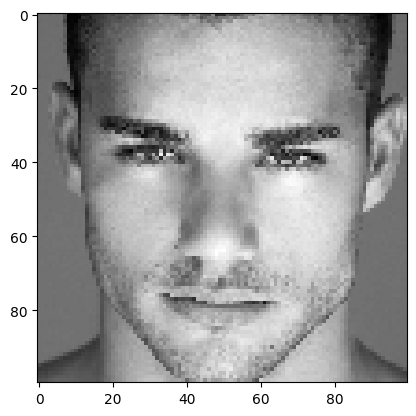

In [ ]:
plt.imshow(image,cmap="gray")

In [99]:
# saving data of dataframe in  apicke file
import pickle

In [103]:
pickle.dump(df, open("./100_100_male_female","wb"))

### Data Preprocessing
- Trasformations, eigenvectors, eigenvalues

In [104]:
# laoding dataset stored in pickle file
df = pickle.load(open("./100_100_male_female","rb"))

In [105]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,9991,9992,9993,9994,9995,9996,9997,9998,9999,gender
0,137,137,138,140,140,141,142,143,142,141,...,103,103,103,103,102,102,102,103,103,male
1,188,149,71,63,49,44,59,58,43,55,...,220,222,222,222,222,222,222,222,222,male
2,12,15,13,14,13,14,25,38,37,36,...,49,50,40,37,45,68,76,64,44,male
3,42,40,39,38,37,39,46,55,63,59,...,33,32,32,31,33,33,32,31,33,male
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,7,23,0,0,0,male


In [195]:
# splitting the data into features and target
X = df.drop("gender",axis=1)
y = df[["gender"]]

In [ ]:
# pip install scikit-learn

In [115]:
from sklearn.preprocessing import MinMaxScaler

In [194]:
X

,0,1,2,3,4,5,6,7,8,9,...,9990,9991,9992,9993,9994,9995,9996,9997,9998,9999
0,137,137,138,140,140,141,142,143,142,141,...,103,103,103,103,103,102,102,102,103,103
1,188,149,71,63,49,44,59,58,43,55,...,220,220,222,222,222,222,222,222,222,222
2,12,15,13,14,13,14,25,38,37,36,...,55,49,50,40,37,45,68,76,64,44
3,42,40,39,38,37,39,46,55,63,59,...,34,33,32,32,31,33,33,32,31,33
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,7,23,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,55,56,55,56,57,50,15,7,13,9,...,88,40,57,53,59,29,39,34,62,54
96,254,254,254,254,254,254,254,254,254,254,...,186,181,180,182,174,172,178,187,192,191
97,87,2,8,22,28,24,1,10,21,7,...,31,2,5,6,7,16,15,31,8,20
98,209,204,206,182,156,144,125,99,88,119,...,146,149,149,148,146,146,146,145,145,144


In [196]:
X = X.reset_index()
X.drop("index",axis=1,inplace=True)

In [197]:
X_scaled = X.copy()
#MinMaxScaler().fit_transform(X)

In [198]:
# zero where the condiition is false and 1 where the condition is true
y_scaled = np.where(y.values=="male",1,0)

In [199]:
# saving the normalize features and labels in a numpy file
numpy_file = np.savez("numpy_array.npz",X=X_scaled,y=y_scaled)

In [200]:
from sklearn.decomposition import PCA

In [259]:
# storing the mean
images_mean = X_scaled.mean(axis=0)

In [201]:
# normalizing further scaled data for eigen faces
X1 = X_scaled -  X_scaled.mean(axis=0)

In [202]:
X1.shape

(200, 10000)

In [203]:
# importing sklearn PCA
# because usign PCA we can find the pixels that are the most important rather then using all pixels
pca = PCA(n_components=None, whiten=True,svd_solver="auto")
x_pca = pca.fit_transform(X1)
pca_explained_variance = pca.explained_variance_ratio_

# cumsum variance o see how many number of components provide how much information
pca_cumsum_variance = np.cumsum(pca_explained_variance)

Text(0, 0.5, 'Cumulative explained variance ration')

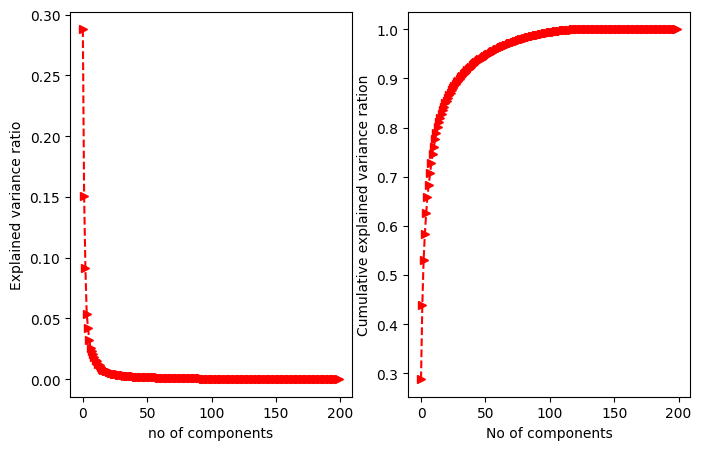

In [204]:
plt.figure(figsize=(8,5))
plt.subplot(1,2,1)
plt.plot(pca_explained_variance[:200],"r>--")
plt.xlabel("no of components")
plt.ylabel("Explained variance ratio")

plt.subplot(1,2,2)
plt.plot(pca_cumsum_variance[:200],"r>--")
plt.xlabel("No of components")
plt.ylabel("Cumulative explained variance ration")

- we can clearly see in right plot that 90% of variance can be defined by using less than 50 features.
- This is the importance of pca. Rather than using 10000 pixels we can do the same thing in only 50 pixels or less.

In [205]:
# Applying PCA with 50 features
x_50_pca = PCA(n_components=50,whiten=True,svd_solver="auto")
x_50_data = x_50_pca.fit_transform(X1)

In [206]:
# now we will inverse transform the x_50_data pca it will give us same 100 by 100 but it will have values for only 50 most important pixels
x_50_pca_inv = x_50_pca.inverse_transform(x_50_data)

In [207]:
# now let's see the shape of x_50_pca_inv, it has 10000 pixels 
x_50_pca_inv.shape

(200, 10000)

In [208]:
X_scaled.loc[11,:]

0       222
1       223
2       210
3       210
4       190
       ... 
9995    209
9996    209
9997    209
9998    209
9999    209
Name: 11, Length: 10000, dtype: uint8

Text(0.5, 1.0, 'real grayscale 100 by 100 image')

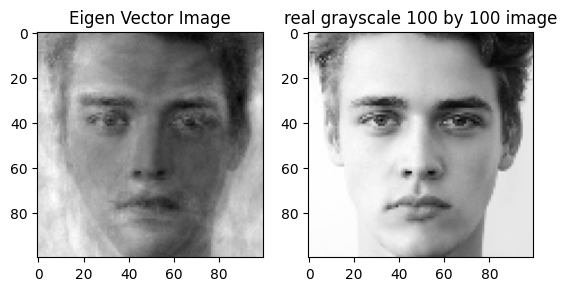

In [ ]:
# visualizing an image from real data 100 by 100 and pca data 100 by 100
plt.subplot(1,2,1)
plt.imshow(x_50_pca_inv[11,:].reshape(100,100),cmap="gray")
plt.title("Eigen Vector Image")
plt.subplot(1,2,2)
plt.imshow(X_scaled.loc[11,:].values.reshape(100,100),cmap="gray")
plt.title("real grayscale 100 by 100 image")

- As we can see by using 50 features we can still preserve the face and can have a structure of face just by using 50 features.


In [210]:
# randomly slecting 10 images
np.random.seed(4)
random_number = np.random.randint(0,200,10)
random_number

array([122, 174, 183, 197, 129, 104,  87,  50, 137,  58])

In [211]:
def label(y):
    if y == 1:
        return "male"
    else:
        return "female"

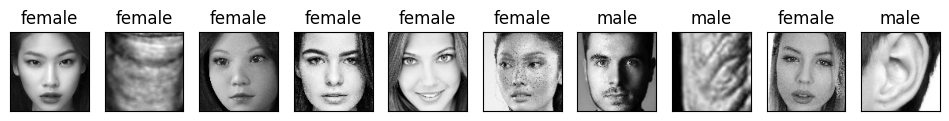

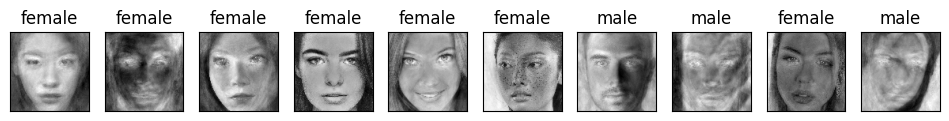

In [ ]:
plt.figure(figsize=(12,10))
for i, img in enumerate(random_number):
    plt.subplot(1,10,i+1)
    plt.imshow(X.loc[img,:].values.reshape(100,100),cmap="gray")
    plt.title(label(y_scaled[img]))
    plt.xticks([])
    plt.yticks([])

plt.show()
print("=" * 50)

plt.figure(figsize=(12,10))
for i, img_number in enumerate(random_number):
    plt.subplot(1,10,i+1)
    plt.imshow(x_50_pca_inv[img_number,:].reshape(100,100),cmap="gray")
    plt.title(label(y_scaled[img_number]))
    plt.xticks([])
    plt.yticks([])


# Model development
- Now, we will use pca transformed data for model develoment

In [ ]:
from sklearn.model_selection import train_test_split


In [215]:
x_50_pca

PCA(n_components=50, whiten=True)

In [223]:
x_50_data.shape

(200, 50)

In [275]:
X_train,X_test,y_train,y_test = train_test_split(x_50_data,y_scaled,test_size=0.2,random_state=31)

In [ ]:
# Initialize the Support Vector Classifier (SVC)
model = SVC(probability=True)

# Train the model on the training data
model.fit(X_train, y_train)

# Calculate accuracy on the training data using score method
train_accuracy = model.score(X_train, y_train)
print(f"Training accuracy: {train_accuracy * 100:.2f}%")

# Calculate accuracy on the testing data using score method
test_accuracy = model.score(X_test, y_test)
print(f"Testing accuracy: {test_accuracy * 100:.2f}%")

Training accuracy: 97.50%
Testing accuracy: 87.50%


c:\Users\SaaD Computer\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [308]:
model.predict_proba(X_test)

array([[0.57786168, 0.42213832],
       [0.45519804, 0.54480196],
       [0.43427087, 0.56572913],
       [0.93872842, 0.06127158],
       [0.94973205, 0.05026795],
       [0.33478452, 0.66521548],
       [0.35601887, 0.64398113],
       [0.59837824, 0.40162176],
       [0.0991558 , 0.9008442 ],
       [0.25144807, 0.74855193],
       [0.04157156, 0.95842844],
       [0.94978309, 0.05021691],
       [0.48996923, 0.51003077],
       [0.87193898, 0.12806102],
       [0.78948799, 0.21051201],
       [0.04156889, 0.95843111],
       [0.04156889, 0.95843111],
       [0.87193898, 0.12806102],
       [0.43427087, 0.56572913],
       [0.63536524, 0.36463476],
       [0.0415863 , 0.9584137 ],
       [0.94969719, 0.05030281],
       [0.13301081, 0.86698919],
       [0.78281252, 0.21718748],
       [0.728025  , 0.271975  ],
       [0.04158575, 0.95841425],
       [0.21861652, 0.78138348],
       [0.72769922, 0.27230078],
       [0.5296343 , 0.4703657 ],
       [0.62933366, 0.37066634],
       [0.

In [227]:
# # # now i will use all 100 by 100 pixel images to see what accuracy they give me
# # X_train,X_test,y_train,y_test = train_test_split(X,y_scaled,test_size=0.2,random_state=31)
# # Initialize the Support Vector Classifier (SVC)
# model = SVC()

# # Train the model on the training data
# model.fit(X_train, y_train)

# # Calculate accuracy on the training data using score method
# train_accuracy = model.score(X_train, y_train)
# print(f"Training accuracy: {train_accuracy * 100:.2f}%")

# # Calculate accuracy on the testing data using score method
# test_accuracy = model.score(X_test, y_test)
# print(f"Testing accuracy: {test_accuracy * 100:.2f}%")

# Making Pipeline for the new images

In [319]:
# load the har cascade model
har_model = cv2.CascadeClassifier("haarcascade_frontalface_default.xml")

# load the svc_model
svc_model = pickle.load(open("svc_model.pkl","rb"))

# loading the pca transformation
pca_transformation = pickle.load(open("pca_model.pkl","rb"))

In [320]:
# setting gender
gender_pre = ["female","male"]
font = cv2.FONT_HERSHEY_SIMPLEX

In [1]:
test_image = "test_images\\1 (4).png"

test_img = cv2.imread(test_image)

color = "bgr"

NameError: name 'cv2' is not defined

In [372]:
def pipline(img,color="rgb"):

    # step # 1 converting a rgb or bgr image into Gray
    if color == "rgb":
        gray = cv2.cvtColor(img,cv2.COLOR_RGB2GRAY)
    else:
        gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)

    # step # 2 detecting the face using harcascade model
    face = har_model.detectMultiScale(gray, scaleFactor=1.1,minNeighbors=5)

    for x,y,w,h in face:
        cv2.rectangle(img,(x,y),(x+w,y+h),(0,255,0),2)

        roi = gray[y:y+h,x:x+w]

        roi = roi /255

    # step 3 shrinking the image if it is large or expanding it if it is small
    if roi.shape[1] > 100:
        roi_resize = cv2.resize(roi,(100,100),cv2.INTER_AREA)

    else:
        roi_resize = cv2.resize(roi,(100,100),cv2.INTER_CUBIC)

    # flatteing the image
    flattened_image = roi_resize.reshape(1,10000)

    mean = images_mean.values.reshape(1,10000)
    # using the mean
    roi_mean = roi_resize.flatten() - mean

    #flattened_image = roi_mean.reshape(1,10000)

    # eigen image
    eigen_image = pca_transformation.transform(flattened_image)

    # prediction on eigen image
    prediction = svc_model.predict(eigen_image)
    print(prediction)

    # probabilities
    probabilities = svc_model.predict_proba(eigen_image)[prediction]

    print("prdiction is",prediction[0])
    if prediction[0] < 1:
        print("it is a female")

    else:
        print("it is a male")

    
    text = f",prob {probabilities}"
    cv2.putText(img, text, (x,y),font,1,(0,255,0),1)

    return img
    

In [373]:
img = pipline(test_img,color=color)

[0]
prdiction is 0
it is a female


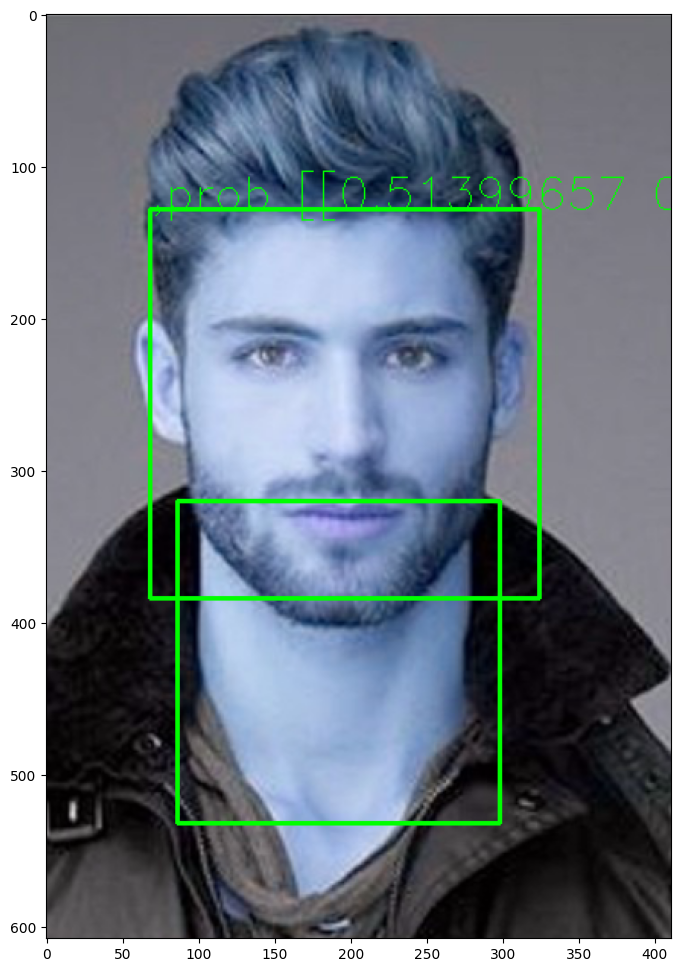

In [ ]:
plt.figure(figsize=(12,12))
plt.imshow(img)